# Engagement 2: Mobile Money Agent Network

## Data Cleaning, Validation and Analysis

This notebook explores and cleans mobile money agent transaction data.
It identifies data-quality issues, standardises transaction records,
merges transactions with the agent register, and produces county-level
and weekly transaction summaries.

In [10]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

In [11]:
txns = pd.read_csv("agent_transactions.csv")
agents = pd.read_csv("agents.csv")

print("Transaction data shape:", txns.shape)
print("Agent register shape:", agents.shape)

display(txns.head())
display(agents.head())

Transaction data shape: (612, 5)
Agent register shape: (20, 3)


,txn_id,agent_id,txn_type,amount,txn_date
0,TX00001,AG009,deposit,353.00,2026-03-03
1,TX00002,AG020,deposit,"1,238.00",2026-04-27
2,TX00003,AG008,DEPOSIT,"9,129.00",2026-04-29
3,TX00004,AG009,deposit,652.00,2026-04-24
4,TX00005,AG009,withdrawal,478.00,2026-04-17


,agent_id,county,onboarded
0,AG001,Mombasa,2024-01-01
1,AG002,Nairobi,2024-02-01
2,AG003,Kisumu,2024-03-01
3,AG004,Kiambu,2024-04-01
4,AG005,Mombasa,2024-05-01


In [12]:
print("TRANSACTION DATA INFORMATION")
txns.info()

print("\nAGENT REGISTER INFORMATION")
agents.info()

print("\nMissing values in transactions:")
display(txns.isnull().sum())

print("\nTransaction type counts:")
display(txns["txn_type"].value_counts(dropna=False))

print("\nTransaction date examples:")
display(txns["txn_date"].head(10))

TRANSACTION DATA INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   txn_id    612 non-null    str    
 1   agent_id  612 non-null    str    
 2   txn_type  612 non-null    str    
 3   amount    590 non-null    float64
 4   txn_date  612 non-null    str    
dtypes: float64(1), str(4)
memory usage: 24.0 KB

AGENT REGISTER INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   agent_id   20 non-null     str  
 1   county     20 non-null     str  
 2   onboarded  20 non-null     str  
dtypes: str(3)
memory usage: 612.0 bytes

Missing values in transactions:


txn_id       0
agent_id     0
txn_type     0
amount      22
txn_date     0
dtype: int64


Transaction type counts:


txn_type
deposit       142
withdrawal    131
Deposit       128
DEPOSIT       111
Withdrawal    100
Name: count, dtype: int64


Transaction date examples:


0    2026-03-03
1    2026-04-27
2    2026-04-29
3    2026-04-24
4    2026-04-17
5    2026-04-23
6    2026-04-02
7    2026-04-12
8    2026-04-04
9    2026-04-17
Name: txn_date, dtype: str

In [13]:
# Count duplicate transaction IDs
duplicate_count = txns.duplicated(
    subset="txn_id",
    keep="first"
).sum()

# Count missing or non-numeric amounts
numeric_amounts = pd.to_numeric(
    txns["amount"],
    errors="coerce"
)

bad_amount_count = numeric_amounts.isna().sum()

# Count transaction types requiring standardisation
standard_types = (
    txns["txn_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "deposit": "Deposit",
        "withdrawal": "Withdrawal"
    })
)

type_changes = (
    txns["txn_type"].astype("string") != standard_types
).sum()

# Count dates using slash separators
slash_dates = (
    txns["txn_date"]
    .astype("string")
    .str.contains("/", na=False)
).sum()

# Count suspicious KES 250,000 amounts
suspicious_amounts = (
    numeric_amounts == 250000
).sum()

# Count unknown agents after accounting for duplicate IDs
unique_txns = txns.drop_duplicates(
    subset="txn_id",
    keep="first"
)

unknown_agents = (
    ~unique_txns["agent_id"].isin(agents["agent_id"])
).sum()

# Create audit table
audit_data = [
    {
        "issue": "Missing or invalid transaction amounts",
        "dimension": "Completeness",
        "column": "amount",
        "rows affected": int(bad_amount_count)
    },
    {
        "issue": "Duplicate transaction IDs",
        "dimension": "Uniqueness",
        "column": "txn_id",
        "rows affected": int(duplicate_count)
    },
    {
        "issue": "Inconsistent transaction type labels",
        "dimension": "Consistency",
        "column": "txn_type",
        "rows affected": int(type_changes)
    },
    {
        "issue": "Transaction dates using slash separators",
        "dimension": "Validity",
        "column": "txn_date",
        "rows affected": int(slash_dates)
    },
    {
        "issue": "Suspicious KES 250,000 amounts",
        "dimension": "Accuracy",
        "column": "amount",
        "rows affected": int(suspicious_amounts)
    },
    {
        "issue": "Transactions with unknown agent IDs",
        "dimension": "Validity",
        "column": "agent_id",
        "rows affected": int(unknown_agents)
    }
]

audit_table = pd.DataFrame(audit_data)

display(audit_table)

,issue,dimension,column,rows affected
0,Missing or invalid transaction amounts,Completeness,amount,22
1,Duplicate transaction IDs,Uniqueness,txn_id,12
2,Inconsistent transaction type labels,Consistency,txn_type,384
3,Transaction dates using slash separators,Validity,txn_date,5
4,"Suspicious KES 250,000 amounts",Accuracy,amount,5
5,Transactions with unknown agent IDs,Validity,agent_id,7


In [14]:
from cleaning_pipeline import clean_agent_data

clean_df, cleaning_log = clean_agent_data(txns, agents)

print("CLEANING PIPELINE LOG")
for item in cleaning_log:
    print("-", item)

print("\nCleaned dataset shape:", clean_df.shape)

display(clean_df.head())

CLEANING PIPELINE LOG
- Original transaction rows: 612
- Duplicate transactions removed: 12
- Transaction types standardised to Deposit and Withdrawal.
- Missing or invalid amounts imputed using median (20 rows).
- Potential amount outliers flagged: 53. Outliers were retained for review.
- Transaction dates standardised to YYYY-MM-DD.
- Transactions with unknown agent IDs: 7.
- Final cleaned transaction rows: 600

Cleaned dataset shape: (600, 8)


,txn_id,agent_id,txn_type,amount,txn_date,amount_imputed,is_outlier,county
0,TX00001,AG009,Deposit,353.00,2026-03-03,False,False,Nakuru
1,TX00002,AG020,Deposit,"1,238.00",2026-04-27,False,False,Mombasa
2,TX00003,AG008,Deposit,"9,129.00",2026-04-29,False,True,Kisumu
3,TX00004,AG009,Deposit,652.00,2026-04-24,False,False,Nakuru
4,TX00005,AG009,Withdrawal,478.00,2026-04-17,False,False,Nakuru


In [15]:
print("POST-CLEANING VALIDATION")

print(
    "Number of rows:",
    len(clean_df)
)

print(
    "Duplicate transaction IDs:",
    clean_df["txn_id"].duplicated().sum()
)

print(
    "Transaction types:",
    clean_df["txn_type"].unique()
)

print(
    "Amount data type:",
    clean_df["amount"].dtype
)

print(
    "Missing amounts:",
    clean_df["amount"].isna().sum()
)

print(
    "Missing transaction dates:",
    clean_df["txn_date"].isna().sum()
)

print(
    "Unknown agent transactions:",
    (clean_df["county"] == "Unknown").sum()
)

print(
    "Imputed amounts:",
    clean_df["amount_imputed"].sum()
)

print(
    "Flagged outliers:",
    clean_df["is_outlier"].sum()
)

POST-CLEANING VALIDATION
Number of rows: 600
Duplicate transaction IDs: 0
Transaction types: <StringArray>
['Deposit', 'Withdrawal']
Length: 2, dtype: str
Amount data type: float64
Missing amounts: 0
Missing transaction dates: 0
Unknown agent transactions: 7
Imputed amounts: 20
Flagged outliers: 53


In [16]:
Path("outputs").mkdir(exist_ok=True)

export_df = clean_df.copy()

export_df["txn_date"] = (
    export_df["txn_date"].dt.strftime("%Y-%m-%d")
)

export_df.to_csv(
    "outputs/agent_transactions_clean.csv",
    index=False
)

print("Cleaned agent transactions exported successfully.")

Cleaned agent transactions exported successfully.


In [17]:

county_summary = (
    clean_df.groupby(["county", "txn_type"])
    .agg(
        total_value=("amount", "sum"),
        number_of_transactions=("txn_id", "count"),
        average_value=("amount", "mean")
    )
    .reset_index()
)

county_summary["total_value"] = county_summary["total_value"].round(2)
county_summary["average_value"] = county_summary["average_value"].round(2)

display(county_summary)


,county,txn_type,total_value,number_of_transactions,average_value
0,Kiambu,Deposit,"334,737.00",43,"7,784.58"
1,Kiambu,Withdrawal,"77,050.50",27,"2,853.72"
2,Kisumu,Deposit,"436,420.50",74,"5,897.57"
3,Kisumu,Withdrawal,"76,374.50",37,"2,064.18"
4,Mombasa,Deposit,"148,986.00",72,"2,069.25"
5,Mombasa,Withdrawal,"368,592.00",61,"6,042.49"
6,Nairobi,Deposit,"543,590.00",118,"4,606.69"
7,Nairobi,Withdrawal,"162,036.00",62,"2,613.48"
8,Nakuru,Deposit,"184,890.00",60,"3,081.50"
9,Nakuru,Withdrawal,"328,594.50",39,"8,425.50"


In [18]:

county_totals = (
    clean_df.groupby("county")
    .agg(
        total_value=("amount", "sum"),
        number_of_transactions=("txn_id", "count"),
        average_value=("amount", "mean")
    )
    .sort_values("total_value", ascending=False)
)

display(county_totals.round(2))


,total_value,number_of_transactions,average_value
county,,,
Nairobi,"705,626.00",180,"3,920.14"
Mombasa,"517,578.00",133,"3,891.56"
Nakuru,"513,484.50",99,"5,186.71"
Kisumu,"512,795.00",111,"4,619.77"
Kiambu,"411,787.50",70,"5,882.68"
Unknown,"27,156.00",7,"3,879.43"


In [19]:

top_county = county_totals["total_value"].idxmax()
top_county_value = county_totals.loc[top_county, "total_value"]

print("County with the highest transaction value:", top_county)
print(f"Total transaction value: KES {top_county_value:,.2f}")


County with the highest transaction value: Nairobi
Total transaction value: KES 705,626.00


In [20]:

clean_df["week"] = (
    clean_df["txn_date"]
    .dt.to_period("W")
    .astype(str)
)

display(clean_df[["txn_date", "week", "county", "amount"]].head())


,txn_date,week,county,amount
0,2026-03-03,2026-03-02/2026-03-08,Nakuru,353.00
1,2026-04-27,2026-04-27/2026-05-03,Mombasa,"1,238.00"
2,2026-04-29,2026-04-27/2026-05-03,Kisumu,"9,129.00"
3,2026-04-24,2026-04-20/2026-04-26,Nakuru,652.00
4,2026-04-17,2026-04-13/2026-04-19,Nakuru,478.00


In [21]:

weekly_pivot = clean_df.pivot_table(
    index="week",
    columns="county",
    values="amount",
    aggfunc="sum",
    fill_value=0
)

display(weekly_pivot.round(2))


county,Kiambu,Kisumu,Mombasa,Nairobi,Nakuru,Unknown
week,,,,,,
2026-02-23/2026-03-01,0.00,"1,893.00","6,759.00","7,046.00","2,743.50",0.00
2026-03-02/2026-03-08,"18,317.00","287,933.00","285,669.50","68,967.00","56,574.00",0.00
2026-03-09/2026-03-15,"267,771.50","23,186.00","30,477.50","52,860.50","28,730.00",0.00
2026-03-16/2026-03-22,"22,054.00","28,125.00","25,144.50","43,107.50","39,795.00","1,639.00"
2026-03-23/2026-03-29,"11,504.00","27,077.00","17,050.00","41,373.50","18,998.50",0.00
2026-03-30/2026-04-05,"22,609.00","41,077.00","38,344.00","282,931.00","18,145.00","8,507.00"
2026-04-06/2026-04-12,"15,030.00","15,341.00","47,092.50","56,786.50","276,609.00","9,824.00"
2026-04-13/2026-04-19,"12,265.00","29,416.00","26,730.00","56,432.50","26,152.50",0.00
2026-04-20/2026-04-26,"24,507.00","37,439.00","16,687.00","65,187.00","30,862.00","1,877.00"


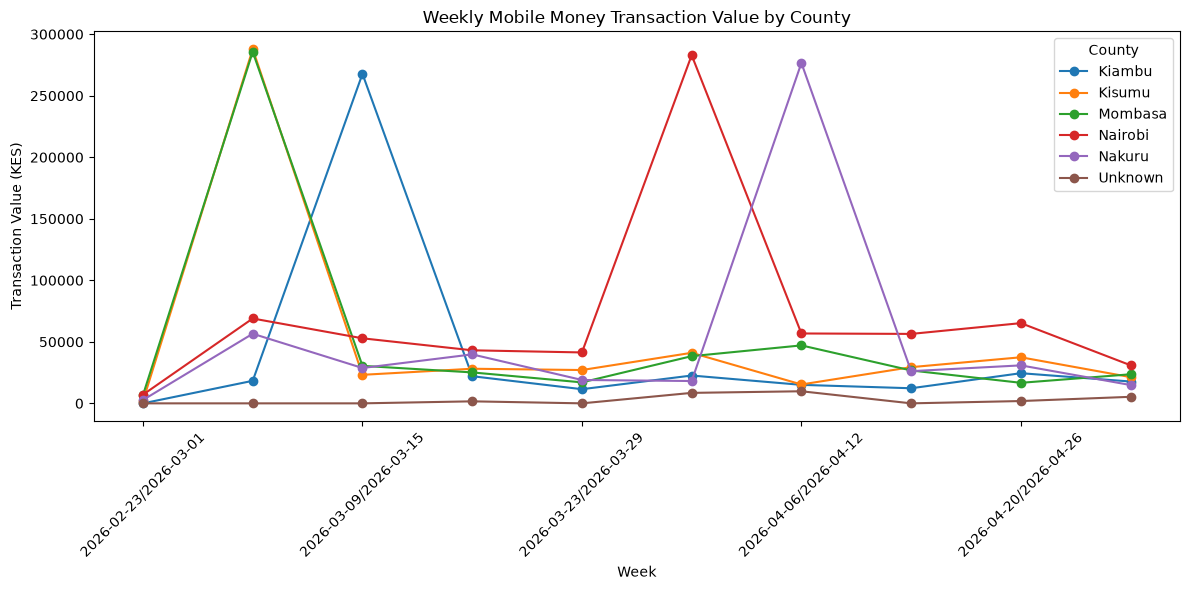

In [22]:

import matplotlib.pyplot as plt

weekly_pivot.plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Weekly Mobile Money Transaction Value by County")
plt.xlabel("Week")
plt.ylabel("Transaction Value (KES)")
plt.xticks(rotation=45)
plt.legend(title="County")
plt.tight_layout()
plt.show()


## Business Insights and Recommendations

In [23]:

total_transactions = len(clean_df)
total_transaction_value = clean_df["amount"].sum()
average_transaction_value = clean_df["amount"].mean()

deposit_data = clean_df[clean_df["txn_type"] == "Deposit"]
withdrawal_data = clean_df[clean_df["txn_type"] == "Withdrawal"]

print("MOBILE MONEY AGENT NETWORK SUMMARY")
print("-----------------------------------")
print(f"Total transactions: {total_transactions:,}")
print(f"Total transaction value: KES {total_transaction_value:,.2f}")
print(f"Average transaction value: KES {average_transaction_value:,.2f}")

print("\nDEPOSITS")
print(f"Number of deposits: {len(deposit_data):,}")
print(f"Deposit value: KES {deposit_data['amount'].sum():,.2f}")

print("\nWITHDRAWALS")
print(f"Number of withdrawals: {len(withdrawal_data):,}")
print(f"Withdrawal value: KES {withdrawal_data['amount'].sum():,.2f}")

print("\nTOP COUNTY")
print(f"{top_county}: KES {top_county_value:,.2f}")


MOBILE MONEY AGENT NETWORK SUMMARY
-----------------------------------
Total transactions: 600
Total transaction value: KES 2,688,427.00
Average transaction value: KES 4,480.71

DEPOSITS
Number of deposits: 373
Deposit value: KES 1,673,902.50

WITHDRAWALS
Number of withdrawals: 227
Withdrawal value: KES 1,014,524.50

TOP COUNTY
Nairobi: KES 705,626.00



# Data Quality Report – Mobile Money Agent Network

Privacy and Data Protection
If the transaction extract also contained customer phone numbers, these would be considered personal data under the Kenya Data Protection Act, 2019, because they could identify or be used to contact an individual. Other identifying fields, such as customer names, national ID numbers and account details, would also require protection. I would protect this information by collecting and using it only for a lawful and clearly stated purpose, limiting access to authorised staff, masking or removing phone numbers from analysis outputs, encrypting data during storage and transfer, and retaining it only for as long as necessary. Where possible, I would use anonymised or aggregated data for reporting and analysis, and ensure that any sharing follows the Act's data protection requirements.

Small legal distinction: A phone number is personal data, but it is not automatically classified as sensitive personal data. The ODPC explicitly lists phone numbers as personal data. The Act also requires purpose limitation, data minimisation, storage limitation and appropriate security safeguards. 
odpc.go.ke+2


You can use the official sources below if you need references:
- Kenya Data Protection Act, 2019 (PDF)
- Office of the Data Protection Commissioner – FAQs

## 1. Completeness

The raw transaction dataset contained **22 missing or invalid transaction amounts**. These values were converted to missing values and imputed using the median transaction amount during the cleaning process. After removing duplicate transactions, **20 records** required imputation. The `amount_imputed` column identifies records that were affected.

## 2. Uniqueness

The raw dataset contained **12 duplicate transaction IDs**. Duplicate records were removed using `txn_id`, retaining one record per transaction. The cleaned dataset contains **600 unique transactions**, with no remaining duplicate transaction IDs.

## 3. Consistency

Transaction type labels were inconsistent, including differences in capitalisation and unwanted spaces. A total of **384 transaction type labels** required standardisation. These were cleaned into two consistent categories: `Deposit` and `Withdrawal`.

## 4. Validity

Transaction amounts were converted into numeric values, and transaction dates were standardised to YYYY-MM-DD format. Five transaction dates originally used slash separators. Transactions linked to agent IDs that were absent from the agent register were retained and assigned the county value `Unknown`. The cleaned dataset contains **7 transactions** associated with unknown agents.

## 5. Accuracy

The dataset contained **5 unusually high transaction amounts of KES 250,000**. These transactions were retained for investigation rather than automatically deleted. The Interquartile Range (IQR) method flagged **53 potential outliers** in total. Unusual values require further investigation before any decision is made to remove or modify them. Median imputation was used for missing or invalid amounts.

## 6. Timeliness

Transaction dates were checked and standardised. The transaction date range was 2026-03-01 - 2026-04-29. The weekly pivot table was used to examine transaction activity over time and compare transaction values across counties.

## Recommendations

1. Require agents to submit transactions using standard transaction type labels.
2. Validate transaction amounts and dates at the point of entry.
3. Investigate unusually high-value transactions before taking action.
4. Maintain an updated agent register to reduce unknown agent references.
5. Perform regular duplicate checks and data-quality audits.
6. Restrict access to sensitive customer information and use aggregated data for reporting.

## Conclusion

The cleaning process improved the consistency, completeness and usability of the mobile money transaction dataset. The cleaned data contains 600 unique transactions and can support county-level reporting and weekly transaction analysis. Records with unknown agents and flagged outliers should receive further investigation.


In [24]:

print("Earliest transaction date:", clean_df["txn_date"].min().date())
print("Latest transaction date:", clean_df["txn_date"].max().date())

print("Original rows:", len(txns))
print("Cleaned rows:", len(clean_df))
print("Duplicate transaction IDs remaining:", clean_df["txn_id"].duplicated().sum())
print("Imputed amounts:", clean_df["amount_imputed"].sum())
print("Flagged outliers:", clean_df["is_outlier"].sum())
print("Unknown agent transactions:", (clean_df["county"] == "Unknown").sum())


Earliest transaction date: 2026-03-01
Latest transaction date: 2026-04-29
Original rows: 612
Cleaned rows: 600
Duplicate transaction IDs remaining: 0
Imputed amounts: 20
Flagged outliers: 53
Unknown agent transactions: 7


In [25]:

export_df = clean_df.drop(columns=["week"], errors="ignore").copy()

export_df["txn_date"] = export_df["txn_date"].dt.strftime("%Y-%m-%d")

export_df.to_csv(
    "outputs/agent_transactions_clean.csv",
    index=False
)

print("Final cleaned dataset saved.")
print("Exported rows:", len(export_df))
print("Exported columns:")
print(export_df.columns.tolist())


Final cleaned dataset saved.
Exported rows: 600
Exported columns:
['txn_id', 'agent_id', 'txn_type', 'amount', 'txn_date', 'amount_imputed', 'is_outlier', 'county']
